# Business and Analytical Context

## Data Understanding

### 1. Project: Mental Health in Technology-related Jobs

#### 1.1 Purpose

This notebook investigates the OSMI 2016 Mental Health in Tech survey dataset to establish whether it is suitable for unsupervised clustering.

The analysis examines the dataset's structure, data types, distributions, missingness, response quality, inconsistencies, conditional survey logic, and relationships between related variables.

The objective is not to prepare the final clustering matrix in this notebook. Instead, it is to establish a defensible understanding of the data and document the exact transformations, exclusions, and feature-engineering decisions required during **data preparation**.

#### 1.2 Analytical Objectives

The investigation addresses the following questions:
1. What does the dataset contain, and what is its structure?
2. Which variables describe respondents, their employment circumstances, workplace mental-health environments, and personal mental-health experiences?
3. How much missingness exists, and which missing values are explained by survey routing?
4. Which variables contain inconsistent, malformed, ambiguous, or non-standardised responses?
5. Which columns contain multiple selections in a single response?
6. Which variables are redundant, excessively sparse, high-cardinality, or unsuitable for clustering?
7. Which variables should be retained, transformed, excluded from clustering, or removed?
8. What decisions must be implemented during data prepartion?

#### 1.3 Clustering Considerations

Four clustering approaches will be investigated, each using a data representation and validation strategy appropriate to its underlying assumptions.

The dataset is predominantly categorical. However, different clustering algorithms interpret categorical information differently. Consequently, the project will investigate both directional clustering and methods that transform categorical observations into alternative representations.

The selected approaches are:

##### 1.3.1 K-Modes - Raw Categorical Data

K- Modes is a centroid-based clustering algorithm designed specifically for categorical data. It uses matching dissimilarity rather than Euclidean distance and represents cluster centres using categorical modes.

Its performance will be evaluated using:
- **Cost/Inertial (Dissimilarity Sum):** The total number of categorical mismatches between observations and their assigned cluster modes. Lower values indicate lower within-cluster dissimilarity. This will be used as the primary elbow-method criterion for selecting the number of clusters.
- **Normalized Mutual Information (NMI) - Stability:** K-Modes will be fitted repeatedly using different random seeds. NMI will compare the resulting cluster assignments. Higher values indicate greater agreement between runs and therefore more stable clustering.
- **Cluster Purity (Feature Dominance):** The distribution of categorical responses within each cluster will be examined to determine whether particular features are disproportionately dominant. This will help establish whether the resulting clusters represent distinct and interpretable respondent profile.

Traditional geometric validation metrics will not be applied directly to the new categorical representation.

##### 1.3.2 K-Means - MCA Components

Multiple Correspondence Analysis (MCA) will transform the categorical variables into continuous numerical coordinates. K-Means will then be applied to the resulting MCA component space.

Its performance will be evaluated using:
- **Silhouette Coefficient:** Measures how well observations fit within their assigned clusters relative to other clusters. Values range from -1 to 1, with higher values generally better separation.
- **Davies-Bouldin Index:** Evaluates the relationship between within-cluster dispersion and separation between clusters. Lower values indicate more distnct clusters.
- **Calinski-Harabasz Index (Variance Ratio Criterion):** Compares between-cluster dispersion with within-cluster dispersion. Higher values generally indicate better-defined clusters.

These geometric metrics are appropriate for the continuous MCA representation, rather than the original categorical observations.

##### 1.3.3 Agglomerative Hierarchical Clustering - Gower Distance

Gower distance will be used to calculate pairwise dissmilarities between observations. It accomodates mixed data types and provides a distance representation suitable for hierarchical clustering.

Its performance will be evaluated using:
- **Cophenetic Correlation Coefficient (CPCC):** Measures the correlation between the original Gower dissimilarities and the cophenetic distances represented by the hierarchical dendrogram. Higher values indicate that the tree better preserves the original pairwise dissimilarities.
- **Silhouette Coefficient (Gower Distance):** The precomputed Gower distance matrix will be supplied directly to the silhouette calculation. Higher values generally indicate better-defined clusters.
- **Hubert's Γ (Gamma) Statistic:*** Evaluates the association between the original pairwise dissimilarities and a model derived from the cluster structure. Higher values indicate stronger agreement between the distance structure and the clustering.

The hierarchical linkage method and its compatibility with the Gower distance representation will be considered when fitting the model.

##### 1.3.4 HDBSCAN - UMAP Embeddings

Uniform Manifold Approximation and Projection (UMAP) will be used to construct a lower-dimensional embedding of the prepared data. HDBSCAN will then identify dense regions in the embedding space without requiring a predefined number of clusters.

HDBSCAN can identify clusters with non-spherical shapes and assign observations that do not belong to sufficiently dense regions to a noise label (-1).

Its perfomance will be evaluated using:
- **Density-Based Clustering Validation (DBCV):** Evaluates cluster density and separation without assuming spherical cluster shapes. Values range from -1 to 1, with higher values generally indicating better density-based cluster validity.
- **Noise Percentage/Coverage:** The proportion if observations assigned the noise label (-1) will be monitored. This indicates how much of the dataset HDBSCAN can assign to clusters. A noise proportion around or below 20-30% will be used as an initial diagnostic target, not as a universal requirement.
- **Cluster Validity and Density Structure:** Cluster persistence, density separation, and the validity of individual clusters will be examined to determine whether the embedding and density parameters produce meaningful groups rather than artificial subdivisions.

The UMAP representation and HDBSCAN parameters will be assessed together because the embedding influences the density structure on which HDBSCAN operates.

#### 1.4 Comparative Evaluation

The four approaches will not be compared using a single metric because they operate on different representations and rely on different clustering assumptions.

Each method will first be evaluated using its appropriate internal validation measures. The final comparison will consider:
- Cluster separation and cohesion.
- Stability and reproducibility.
- Cluster size and distribution.
- Noise or unassigned observations, where applicable.
- Feature dominance and interpretability.
- Whether the resulting clusters represent meaningful respondent profiles.
- Sensitivity to model and representation parameters.

The objective is to select a clustering solution that is statistically defensible, stable, interpretable, and appropriate for the structure of the survey data.

#### 1.5 Scope and Ethical Considerations

The survey includes sensitive mental-health information. The analysis will not interpret survey responses as clinical diagnoses, infer medical conditions, or treat demographic characteristics as indicators of mental-health status.

The clustering objective is to identify patterns in survey responses and workplace experiences, not to diagnose individuals or make decisions about their employment.

### 2. Import Libraries and Load the Dataset



In [161]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")

data_path = "../data/raw/mental-heath-in-tech-2016_20161114.csv"
FIGURES_PATH = "../reports/figures"

df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
df.head()

Dataset shape: 1,433 rows x 63 columns


,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",Do you think that discussing a mental health disorder with your employer would have negative consequences?,Do you think that discussing a physical health issue with your employer would have negative consequences?,Would you feel comfortable discussing a mental health disorder with your coworkers?,Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?,Do you feel that your employer takes mental health as seriously as physical health?,Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?,Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,Do you know local or online resources to seek help for a mental health disorder?,"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?","If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?","If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?","If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",Do you believe your productivity is ever affected by a mental health issue?,"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",Do you have previous employers?,Have your previous employers provided mental health benefits?,Were you aware of the options for mental health care provided by your previous employers?,Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?,Did your previous employers provide resources to learn more about mental health issues and how to seek help?,Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?,Do you think that discussing a mental health disorder with previous employers would have negative consequences?,Do you think that discussing a physical health issue with previous employers would have negative consequences?,Would you have been willing to discuss a mental health issue with your previous co-workers?,Would you have been willing to discuss a mental health issue with your direct supervisor(s)?,Did you feel that your previous employers took mental health as seriously as physical health?,Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?,Would you be willing to bring up a physical health issue with a potential employer in an interview?,Why or why not?,Would you bring up a mental health issue with a potential employer in an interview?,Why or why not?.1,Do you feel that being identified as a person with a mental health issue would hurt your career?,Do you think that team members/co-workers would view you more negatively if they knew you suffered from a menta

#### 2.1 Initial Dataset Structure

The dataset contains **1,433 observations and 63 variables**.

Each row represents a survey respondent. The columns describe employment circumstances, workplace policies and experiences, personal mental-health experiences, demographic information, and work arrangements.

The dataset is not a conventional rectangular survey in which every repsondent answers every question. Several questions are conditional on earlier responses. This is important because missing values cannot automatically be interpreted as non-response.

### 3. Inspect the Dataset Structure

In [162]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                                                                                                                                                                            Non-Null Count  Dtype  
---  ------                                                                                                                                                                            --------------  -----  
 0   Are you self-employed?                                                                                                                                                            1433 non-null   int64  
 1   How many employees does your company or organization have?                                                                                                                        1146 non-null   str    
 2   Is your employer primarily a tech company/organization?                

In [163]:
pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_percentage", ascending=False)

,data_type,non_missing,missing,missing_percentage,unique_values
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",str,144,1289,89.95,3
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",str,204,1229,85.76,4
Is your primary role within your company related to tech/IT?,float64,263,1170,81.65,2
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,float64,287,1146,79.97,2
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",str,287,1146,79.97,5
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?",str,287,1146,79.97,5
"If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",str,287,1146,79.97,4
Do you know local or online resources to seek help for a mental health disorder?,str,287,1146,79.97,3
Do you believe your productivity is ever affected by a mental health issue?,str,287,1146,79.97,4
"If maybe, what condition(s) do you believe you have?",str,322,1111,77.53,99


#### 3.1 Initial Structural Observations

The dataset is dominated by object-type (str) categorical variables. Some binary questions are represented numerically, while others use text labels.

The following structural characteristics require attention during preparation:
- Binary variables are not represented consistently across the dataset.
- Several categorical variables contain multiple response options within one cell.
- Some categorical variables have very high cardinality because they contain free-text responses.
- Missingness varies substantially across variables.
- Several questions are conditional and therefore have structurally missing responses.
- The age variable contains implausible values.
- The gender variable contains inconsistent spelling, capitalisation, terminology, and free-text responses.

These issues will be investigated individually rather than corrected indiscriminately.

### 4. Classify the Variables

#### 4.1 Variable Classification

For analytical purposes, the variables can be grouped into the following domains:

| Domain | Examples | Analytical role |
| :--- | :--- | :--- |
| Employment circumstances | Self-employment, company size, technology employer, work position | Employment context |
| Current workplace environment | Benefits, awareness, resources, confidentiality, disclosure consequences | Workplace support and culture |
| Previous workplace environment | Previous employer benefits, resources, confidentiality, disclosure experiences | Historical workplace context |
| Disclosure and stigma | Disclosure to colleagues, supervisors, clients, interviewers, career concerns | Perceived stigma and disclosure |
| Mental-health history | Family history, past/current disorder, professional diagnosis, treatment | Personal mental-health context |
| Work-related impact | Productivity, work interference, percentage of work time affected | Functional impact |
| Demographics and geography | Age, gender, country, state | Respondent characteristics |
| Work arrangements | Remote work, work position | Employment characteristics |
| Qualitative explanations | Interview explanations and condition descriptions | Qualitative context |

The distinction between a varaible's analytical value and its suitability as a clustering feature will be maintained. For example, demographic variables can help describe clusters without necessarily being included in the clustering distance calculation.

### 5. Data Quality: Duplicates and Structural Problems

#### 5.1 Duplicate Observations

Exact duplicate rows can artificially increase the influence of repeated observations in clustering. They must therefore be identified before modelling.

In [164]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

Exact duplicate rows: 0


The dataset contains **zero exact duplicate rows**. No observations need to be removed on the basis of exact row duplication.

#### 5.2 Duplicate Columns

Identical columns can introduce unnecessary weighting of the same information in a clustering algorithm.

In [165]:
[
    (df.columns[i], df.columns[j])
    for i in range(df.shape[1])
    for j in range(i + 1, df.shape[1])
    if df.iloc[:, i].equals(df.iloc[:, j])
]

[]

There are **no exact duplicate columns**. However, the absence of exact duplicates does not establish that conceptually related questions are interchangeable. Those relationships are investigated separately below.

### 6. Missing-Value Investigation

#### 6.1 Overall Missingness

Missing values are particularly important in this dataset because the survey uses conditional questions.

A respondent may have a missing answer because:
- The question was not applicable to their circumstances.
- A preceding response routed them away from the question.
- The repsondent did not provide an answer.
- The survey design limited the question to a particular respondent group.

These situations must not be treated as equivalent.

In [166]:
(
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100,
        "observed_count": df.notna().sum(),
        "unique_observed": df.nunique(dropna=True)
    })
    .sort_values("missing_percentage", ascending=False)
    .round(2)
)

,missing_count,missing_percentage,observed_count,unique_observed
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",1289,89.95,144,3
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",1229,85.76,204,4
Is your primary role within your company related to tech/IT?,1170,81.65,263,2
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,1146,79.97,287,2
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",1146,79.97,287,5
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?",1146,79.97,287,5
"If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?",1146,79.97,287,4
Do you know local or online resources to seek help for a mental health disorder?,1146,79.97,287,3
Do you believe your productivity is ever affected by a mental health issue?,1146,79.97,287,4
"If maybe, what condition(s) do you believe you have?",1111,77.53,322,99


C:\Users\User\AppData\Local\Temp\ipykernel_7680\2492413505.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


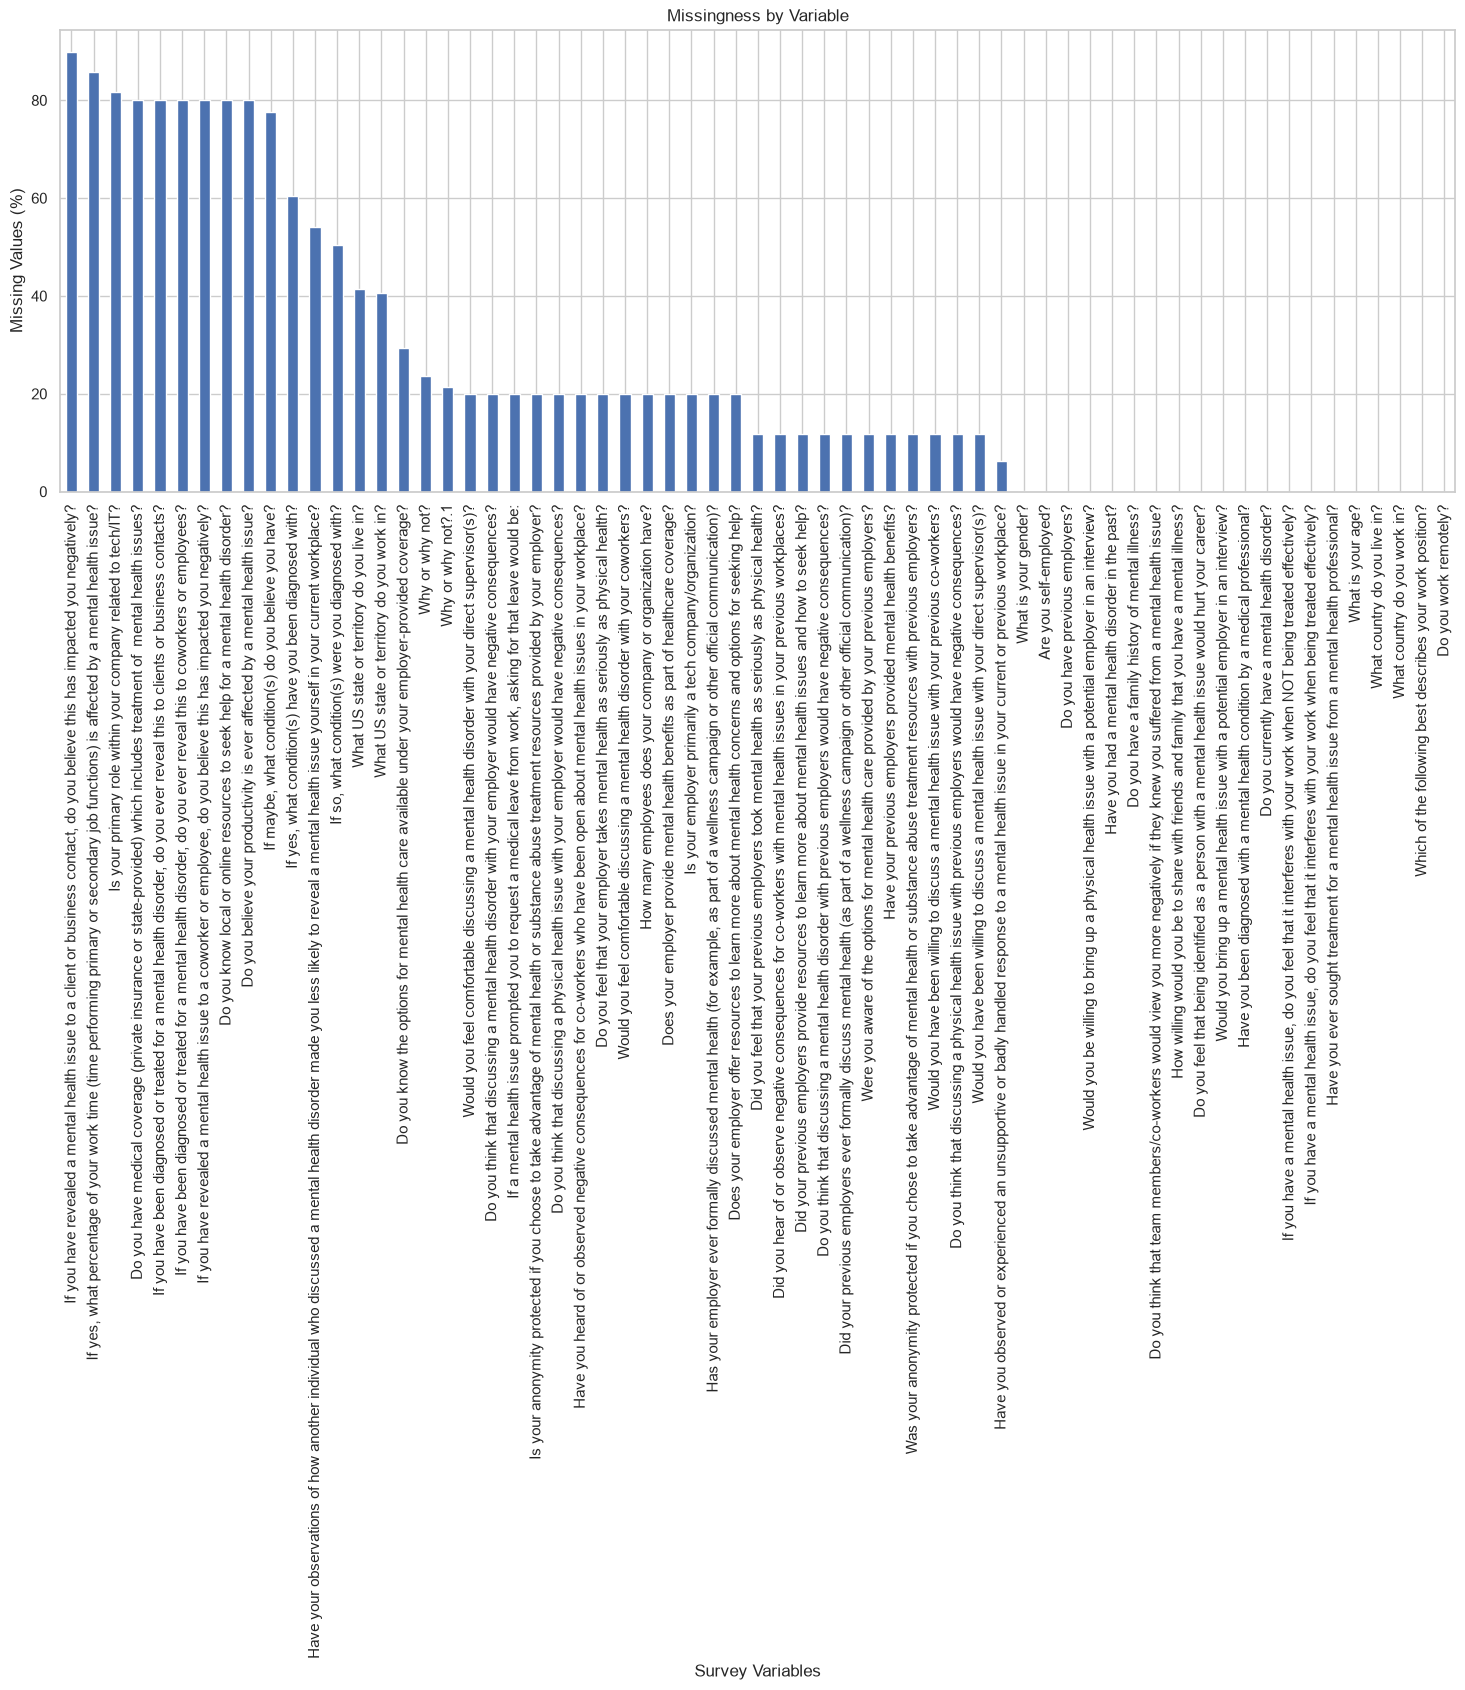

In [174]:
(
    df.isna().mean()
    .sort_values(ascending=False)
    .mul(100)
    .plot(
        kind="bar",
        figsize=(18, 6),
        title="Missingness by Variable"
    )
)

plt.ylabel("Missing Values (%)")
plt.xlabel("Survey Variables")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "missingness_by_colum.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

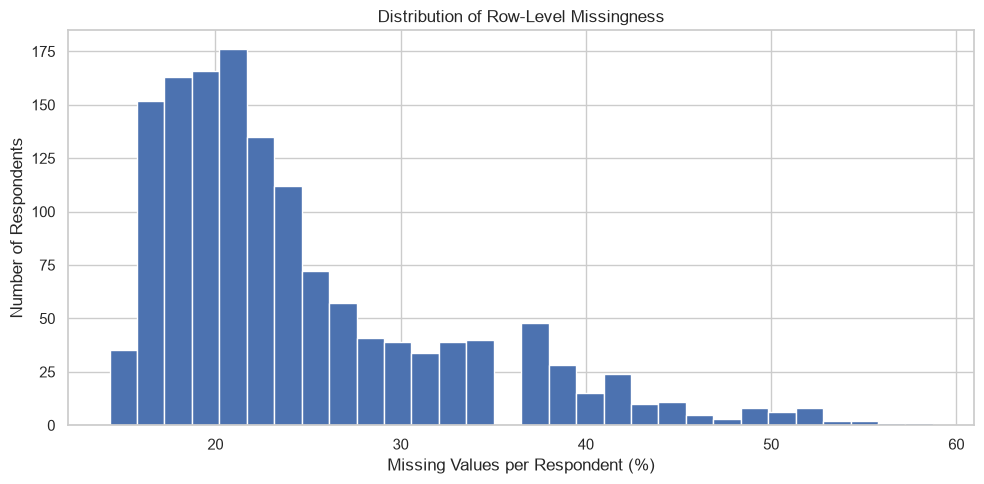

In [175]:
(
    df.isna().mean(axis=1)
    .mul(100)
    .plot(
        kind="hist",
        bins=30,
        figsize=(10, 5),
        title="Distribution of Row-Level Missingness"
    )
)

plt.xlabel("Missing Values per Respondent (%)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "row_missingness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#### 6.2 Missingness Findings

The missingness profile reveals several groups of variables:

| Missingness | Variables or groups | Initial interpretation |
| :--- | :--- | :--- |
| 0–6.2% | Most core mental-health, demographic and workplace-experience questions | Generally well populated |
| 11.8% | Previous-employer questions | Associated with respondents who have no previous employers |
| 20.0% | Current-employer questions | Associated with self-employed respondents |
| 21–29.3% | Interview explanation fields and employer coverage awareness | Requires question-specific interpretation |
| 40–41% | US state or territory | Geographic question only applicable to US respondents |
| 50–60% | Diagnosis-related condition descriptions | Conditional responses |
| 54.2% | Influence of observed workplace disclosure | Requires investigation of applicability |
| 77–80% | Several self-employment-related questions and follow-up fields | Strongly conditional |
| 85.8–90% | Work-time percentage and client disclosure impact | Highly conditional and sparse |

The following investigations determine whether these missing values are structurally explained.

#### 6.3 Current-Employer Questions and Self-Employment

In [176]:
pd.crosstab(
    df["Are you self-employed?"],
    df[
        "Does your employer provide mental health "
        "benefits as part of healthcare coverage?"
    ].isna(),
    margins=True
)

Does your employer provide mental health benefits as part of healthcare coverage?,False,True,All
Are you self-employed?,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


In [177]:
pd.crosstab(
    df["Are you self-employed?"],
    df["Is your employer primarily a tech company/organization?"].isna(),
    margins=True
)

Is your employer primarily a tech company/organization?,False,True,All
Are you self-employed?,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


In [178]:
pd.crosstab(
    df["Are you self-employed?"],
    df["How many employees does your company or organization have?"].isna(),
    margins=True
)

How many employees does your company or organization have?,False,True,All
Are you self-employed?,,,
0,1146,0,1146
1,0,287,287
All,1146,287,1433


The dataset contains:
- 1,146 respondents who are not self-employed.
- 287 respondents who are self-employed.

The current-employer questions contain 287 missing responses, corresponding to the self-employed group.

This is consistent with survey routing: respondents who do not have a conventional current employer cannot answer questions about their employer's benefits, workplace policies, or employer-provided resources in the same way as employees.

**Data-Preparation Decision**
- Preserve the self-employment variable.
- Retain current-employer variables for the employee population.
- Do not impute the structurally missing current-employer responses.
- Do not convert these missing values into `No`.
- For the full clustering dataset, exclude current-employer variables whose values are unavailable for the self-employed group if their missingness cannot be represented meaningfully without distorting the clustering.
- The current-employer domain should be represented through features with defensible coverage across the intended clustering population.

#### 6.4 Previous-Employer Questions

In [179]:
pd.crosstab(
    df["Do you have previous employers?"],
    df["Have your previous employers provided mental health benefits?"].isna(),
    margins=True
)

Have your previous employers provided mental health benefits?,False,True,All
Do you have previous employers?,,,
0,0,169,169
1,1264,0,1264
All,1264,169,1433


There are 169 respondents who reported having no previous employers. The previous-employer questions contain 169 missing responses. This is consistent with conditional survey routing.

**Data-Preparation Decision**
- Retain `Do you have previous employers?`.
- Do not impute previous-employer responses for respondents who have never had previous employers.
- Do not convert these missing values into negative responses.
- Previous-employer variables should not be included as ordinary categorical features in the full dataset unless the representation explicitly preserves their applicability.
- They can be retained for a separate employee-history analysis or used to construct carefully defined features that distinguish `not applicable` from actual responses.

#### 6.5 Self-Employment-Specific Questions

In [182]:
pd.crosstab(
    df["Are you self-employed?"],
    df[
        "Do you have medical coverage (private insurance or "
        "state-provided) which includes treatment of  mental "
        "health issues?"
    ].isna(),
    margins=True
)

Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,False,True,All
Are you self-employed?,,,
0,0,1146,1146
1,287,0,287
All,287,1146,1433


The medical-coverage question has 1,146 missing values and 287 observed responses. The missingness is concentrated in the non-self-employed group.

This is a survey routing pattern, not evidence that 80% if respondents lack medical coverage.

The same pattern applies to several variables with 1,146 missing values, including:
- knowledge of local or online mental-health resources.
- Disclosure to clients or business contacts.
- Disclosure to coworkers or employees.
- Productivity affected by mental-health issues.

**Data-Preparation Decision**

These variables nust not be interpreted as having 80% ordinary non-response. Their applicability is restricted by the survey design. Because their coverage is limited to a subgroup, they should not be inserted into the full-population clustering matrix as though they were universally observed. Retain them for subgroup analysis and document their restricted population.

### 6.6 Productivity Follow-Up

In [183]:
pd.crosstab(
    df[
        "Do you believe your productivity is ever affected by "
        "a mental health issue?"
    ],
    df[
        "If yes, what percentage of your work time (time "
        "performing primary or secondary job functions) is "
        "affected by a mental health issue?"
    ].isna(),
    margins=True
)

"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",False,True,All
Do you believe your productivity is ever affected by a mental health issue?,,,
No,0,14,14
Not applicable to me,0,31,31
Unsure,0,38,38
Yes,204,0,204
All,204,83,287


The work-time percentage question has 1,229 missing values. It is a follow-up to the productivity question and is answered only when repsondents indicate that productivity is affected.

The observed responses are:
- 1-25%
- 26-50%
- 51-75%
- 76-100%

The percentage variable is therefore a conditional measure, not a general measure of work impact.

**Data-Preparation Decision**
- Retain `productivity_affected` in the cleaned analytical dataset.
- Use it for descriptive analysis and analysis of the subgroup to which the question applies.
- Exclude it from the full-population clustering feature matrix because its coverage is restricted by survey routing.
- Retain `work_time_affected_pct` for descriptive analysis of respondents who report productivity effects.
- Exclude `work_time_affected_pc`t from the full-population clustering matrix because it is both highly sparse and conditional.
- Do not impute either field or interpret structural missingness as a negative response.

**Replacement for the final feature lists:** remove `productivity_affected` from the full-population clustering candidates and explicitly list it among the retained subgroup-analysis fields.

### 6.7 Client Disclosure Impact

The question about negative consequences after disclosing a mental-health issue to clients or business contacts has 90% missingness.

It is a follow-up question that is only meaningful for respondents who have disclosed a mental-health issue to clients or business contacts.

The observed responses are too limited to provide a stable, general-population clustering feature.

**Data-Preparation Decision**

Remove this variable from the clustering feature set. Retain it only if required for a separate descriptive analysis of respondents who disclosed their condition.

#### 6.8 Workplace Observation and Disclosure Influence

In [184]:
pd.crosstab(
    df[
        "Have you observed or experienced an unsupportive or "
        "badly handled response to a mental health issue in your "
        "current or previous workplace?"
    ],
    df[
        "Have your observations of how another individual who "
        "discussed a mental health disorder made you less likely "
        "to reveal a mental health issue yourself in your current "
        "workplace?"
    ],
    margins=True,
    dropna=False
)

Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?,Maybe,No,Yes,NaN,All
Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?,,,,,
Maybe/Not sure,82,137,53,74,346
No,0,0,0,567,567
"Yes, I experienced",33,41,65,28,167
"Yes, I observed",62,56,128,18,264
NaN,0,0,0,89,89
All,177,234,246,776,1433


The question about whether observed disclosure made respondents less likely to disclose themselves has 54.2% missingness.

Unlike the current-employer and previous-employer missingness patterns, this variable is not explained simply by self-employment or previous-employer status. It should be treated as a conditional or incomplete response whose applicability needs to be preserved during preparation.

Its observed responses are meaningful, but its coverage is too limited for inclusion as a general feature in the full clustering matric.

**Data-Preparation Decision**

Remove this variable from the full clustering feature set. Retain it for a separate analysis of workplace disclosure experiences.

### 7. Age Investigation

#### 7.1 Age Distribution and Validity

Age is a numerical variable and may contribute useful information about respondent characteristics. However, implausible values can distort numerical scaling and subsequent clustering.

In [185]:
df["What is your age?"].describe()

count    1433.000000
mean       34.286113
std        11.290931
min         3.000000
25%        28.000000
50%        33.000000
75%        39.000000
max       323.000000
Name: What is your age?, dtype: float64

In [328]:
df.loc[
    ~df["What is your age?"].between(18, 75),
    ["What is your age?", "What is your gender?"]
]

,What is your age?,What is your gender?
93,17,male
372,99,Other
564,323,Male
656,3,Male
808,15,male


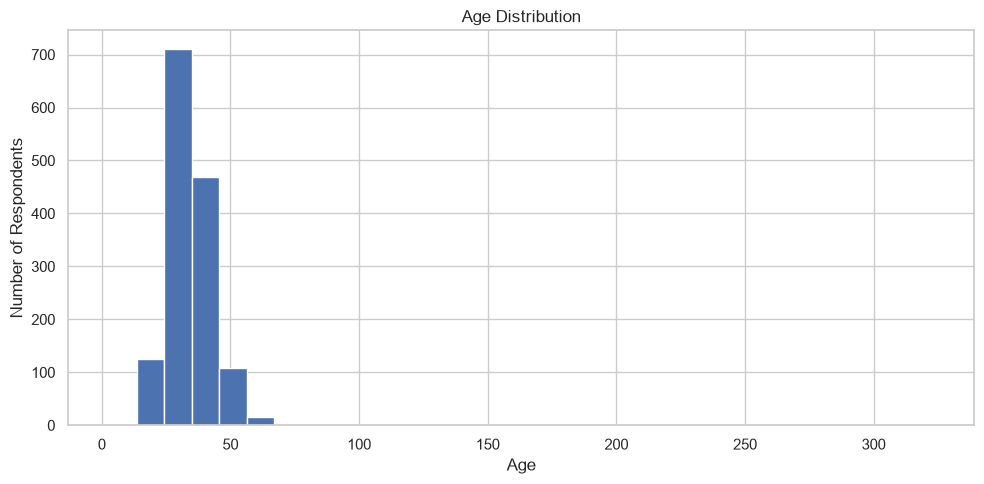

In [195]:
df["What is your age?"].plot(
    kind="hist",
    bins=30,
    figsize=(10, 5),
    title="Age Distribution"
)

plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The age column contains five implausible observations:

| Age | Assessment |
| :--- | :--- |
| 3 | Implausible for this respondent survey |
| 15 | Outside the intended adult respondent population |
| 17 | Outside the intended adult respondent population |
| 99 | Outside the intended adult respondent population |
| 323 | Impossible age; likely data-entry error |

The remaining values fall within the adult age range.

**Data-Preparation Decision**
- Convert 3, 15, 17, 99, 323 to missing.
- Do not attempt to guess the intended ages.
- Preserver the remaining valid ages.
- Use a robust imputation strategy only if age is retained in the clustering feature set.
- Do not include age in the feature matrix. Most features in the OSMI dataset are categorical or binary text (e.g., `Yes / No` responses to having a diagnosis, or `True / False` multi-label flags for disorders). Age is a continuous numeric variable. Continuous variables naturally scale completely differently than binary flags. Even after scaling (like `StandardScaler`), the mathematical "distance" between age 22 and age 45 can completely drown out the distance between someone having an anxiety disorder or not.
- Age should also be evaluated as a cluster-description variable rather than automatically given influence in clustering.

### 8. Gender Inverstigation

#### 8.1 Gender Response Quality

Gender was collected as free text. This creates a high-cardinality variable containing spelling variants, inconsistent capitalisation, abbreviations, identity descriptions, and responses that do not fit a simple binary classification.

In [197]:
(
    df["What is your gender?"]
    .value_counts(dropna=False)
    .to_frame("frequency")
)

,frequency
What is your gender?,
Male,610
male,249
Female,153
female,95
M,86
m,79
F,38
f,23
Male,11


In [198]:
df.loc[
    df["What is your gender?"].isna()
    | df["What is your gender?"].astype(str).str.contains(r"\|", regex=True),
    ["What is your gender?"]
]

,What is your gender?
302,NaN
643,NaN
925,M|
1312,NaN


The gender variable has:
- 70 distinct non-missing responses.
- 3 missing responses.
- Numerous spelling and capitalisation variants.
- Several responses that describe transgender, non-binary, genderfluid, agender, and other identities.
- Some responses that contain explanatory text rather than a concise category.
- One malformed value: `M|`.

A simple binary mapping would erase meaningful distinctions and incorrectly classify some respondents.

**Data-Preparation Decision**
- Standardise whitespace and capitalisation.
- Correct obvious typographical variants only when the intended response is unambiguous.
- Map clear equivalents such as `M`, `M|`, `m`, `Male`, and `male` to a consistent male category.
- Map clear equivalents suc as `F`, `f`, `Female`, and `female` to a consistent female category.
- Map other genders to a consistent other category.
- Do not use the raw gender field as a clustering feature. Its free-text nature and sensitive demographic content make it more appropriate for descriptive profiling after clusters have been established.

### 9. Multi-Select and Pipe-Separated Responses

#### 9.1 Why Pipe-Separated Responses Require Special Treatment

A pipe character (`|`) is used in the dataset to separate multiple selected responses within a single cell.

Treating each complete combination as a separate category would create unnecessary cardinality. For example:
- `Anxiety Disorder|Mood Disorder`
- `Anxiety Disorder|Mood Disorder|ADHD`
- `Mood Disorder|ADHD`

These are not three unrelated categories. They are combinations of selections from a shared set of possible conditions.

The pipe-separated fields must therefore be investigated and transformed into multi-label representations during data preparation.

In [199]:
pd.DataFrame({
    "pipe_response_count": df.apply(
        lambda column: column.astype("string").str.contains(
            r"\|", regex=True, na=False
        ).sum()
    ),
    "unique_values": df.nunique(dropna=True),
    "missing_percentage": df.isna().mean().mul(100).round(2)
}).query("pipe_response_count > 0")

,pipe_response_count,unique_values,missing_percentage
"If yes, what condition(s) have you been diagnosed with?",367,128,60.36
"If maybe, what condition(s) do you believe you have?",207,99,77.53
"If so, what condition(s) were you diagnosed with?",392,116,50.38
What is your gender?,1,70,0.21
Which of the following best describes your work position?,616,264,0.00


The investigation identifies four fields containing pipe characters:

| Variable | Responses containing pipe | Interpretation |
| :--- | :---: | :--- |
| Diagnosed conditions (current-status follow-up) | 367 | Multiple conditions selected |
| Suspected conditions (maybe-status follow-up) | 207 | Multiple conditions selected |
| Professionally diagnosed conditions | 392 | Multiple conditions selected |
| Work position | 616 | Multiple roles selected |
| Gender | 1 | Malformed trailing delimiter, not a multi-select field |

#### 9.2 Investigate Condition Responses

In [215]:
for column in [
    "If yes, what condition(s) have you been diagnosed with?",
    "If maybe, what condition(s) do you believe you have?",
    "If so, what condition(s) were you diagnosed with?"
]:
    print(f"\n{column}")
    display(
        df[column]
        .dropna()
        .astype(str)
        .str.split("|")
        .explode()
        .str.strip()
        .value_counts()
        .to_frame("frequency")
    )


If yes, what condition(s) have you been diagnosed with?


,frequency
"If yes, what condition(s) have you been diagnosed with?",
"Mood Disorder (Depression, Bipolar Disorder, etc)",412
"Anxiety Disorder (Generalized, Social, Phobia, etc)",345
Attention Deficit Hyperactivity Disorder,121
Post-traumatic Stress Disorder,69
Obsessive-Compulsive Disorder,45
Substance Use Disorder,39
Stress Response Syndromes,38
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",35
Addictive Disorder,35



If maybe, what condition(s) do you believe you have?


,frequency
"If maybe, what condition(s) do you believe you have?",
"Mood Disorder (Depression, Bipolar Disorder, etc)",219
"Anxiety Disorder (Generalized, Social, Phobia, etc)",192
Attention Deficit Hyperactivity Disorder,58
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",42
Stress Response Syndromes,40
Obsessive-Compulsive Disorder,30
Post-traumatic Stress Disorder,26
Addictive Disorder,24
Substance Use Disorder,16



If so, what condition(s) were you diagnosed with?


,frequency
"If so, what condition(s) were you diagnosed with?",
"Mood Disorder (Depression, Bipolar Disorder, etc)",526
"Anxiety Disorder (Generalized, Social, Phobia, etc)",373
Attention Deficit Hyperactivity Disorder,134
Post-traumatic Stress Disorder,70
Obsessive-Compulsive Disorder,40
Stress Response Syndromes,31
"Personality Disorder (Borderline, Antisocial, Paranoid, etc)",28
Substance Use Disorder,26
"Eating Disorder (Anorexia, Bulimia, etc)",18


The condition fields contain a mixture of:
1. Standard survey categories, such as anxiety disorders, mood disorders, ADHD, PTSD, OCD, and eating disorders.
2. Alternative descriptions of similar conditions, such as `Depresion` and `Mood Disorder`.
3. Spelling and capitalisation variations.
4. Free-text explanations and qualifications.
5. Responses that do not map cleanly to the suvey's predefined categories.

The three condition columns also represent different concepts:
- Conditions reported in relation to current mental-health status.
- Conditions respondents believe they may have.
- Conditions respondents report having received a professional diagnosis for.

They must not be merged into one undifferentiated diagnosis variable.

**Data-Preparation Decision**
- Split the three condition fields on `|`.
- Trim whitespace from every resulting selection.
- Standardise obvious spelling and capitalisation variants.
- Map clearly equivalent labels to a consistent condition category only where the meaning is unambiguous.
- Preserve the distinction between self-suspected conditions and professionally diagnosed conditions.
- Convert each condition field into a multi-hot representation if is retained for analysis.
- Do not treat the absence of a selected condition as proof that a repsondent does not have that condition.
- Do not infer a professional diagnosis from a self-reported suspected condition.
- Because these condition variables are highly sparse, high-cardinality, and clinically sensitive, they should not be included as raw categorical fields in the main clustering matrix. Retain them for descriptive profiling or a separate, carefully designed feature-engineering analysis.

#### 9.3 Investigate Work-Position Responses

In [231]:
(
    df["Which of the following best describes your work position?"]
    .dropna()
    .astype(str)
    .str.split("|")
    .explode()
    .str.strip()
    .value_counts()
    .to_frame("frequency")
)

,frequency
Which of the following best describes your work position?,
Back-end Developer,737
Front-end Developer,502
DevOps/SysAdmin,282
Supervisor/Team Lead,277
Other,187
Support,168
One-person shop,161
Designer,135
Executive Leadership,101


The work-position field contains 264 distinct complete response combinations. A substantial proportion of respondents selected more than one role.

The most frequent individual roles include:
- Back-end Developer
- Front-end Developer
- Other
- Supervisor/Team Lead
- DevOps/SysAdmin
- One-person shop
- Executive Leadership
- Support
- Designer
- Dev Evangelist/Advocate

The complete combinations should not be treated as independent categories.

**Data-Preparation Decision**
- Split the field on `|`.
- Trim whitespace.
- Standardise role labels.
- Convert the selections into multi-hot role indicators if the field is retained.
- Preserve multiple roles rather than forcing respondents into one role.
- Review rare role categories and consolidate them only when there is a defensible conceptual basis.
- Do not include the original unsplit field in clustering.

### 10. Free-Text Response Investigation

#### 10.1 Interview Explanations

The dataset contains two free-text fields:
- `Why or why not?` - explanation of willingness to discuss a physical health issue in an interview.
- `Why or why not?.1` - explanation of willingness to discuss a mental-health issue in an interview.

These fields are deliberately paired. They represent different subjects and should not be treated as duplicate columns.

In [243]:
for column in ["Why or why not?", "Why or why not?.1"]:
    print(f"\n{column}")
    print(f"Missing: {df[column].isna().sum():,}")
    print(f"Unique responses: {df[column].nunique(dropna=True):,}")

    display(
        df[column]
        .dropna()
        .astype(str)
        .str.strip()
        .value_counts()
        .head(20)
        .to_frame("frequency")
    )



Why or why not?
Missing: 338
Unique responses: 1,085


,frequency
Why or why not?,
Not relevant,3
Fear of discrimination,3
I don't know,3
Fear of not getting the job,3
None of their business,2
None of their business.,2
bias,2
honesty,2
"It would depend on the health issue. If there is a health issue that would not immediately affect my job performance, such as diabetes, I would not bring it up during the interview. If it was something more severe, such as narcolepsy, I might bring it up depending on how controlled it was.",1



Why or why not?.1
Missing: 307
Unique responses: 1,080


,frequency
Why or why not?.1,
Stigma,14
Stigma.,10
Same as above,7
See above,4
Fear of discrimination,4
Fear of not getting the job,4
Same reason as above.,3
same as above,3
Same as above.,3


Both fields contain hundreds of missing and more than 1,000 distinct non-missing responses. They contain qualitative explanations rather than standardised categories.

Raw text cannot be used directly as a K-Modes feature. Converting every unique sentence into a category would create extreme sparsity and noise.

**Data-Preparation Decision**
- Retain both columns in the source-preserving analytical dataset.
- Standardise empty strings and whitespace.
- Do not use the raw text fields in the main clustering matrix.
- Exclude them from the clustering feature set.
- They may be used for qualitative interpretation or a separate NLP analysis if that becomes a distinct project objective.
- Do not impute missing text.

### 11. Categorical Response Consistency

#### 11.1 Standardised and Non-Standardised Categories

Categorical variables must be inspected for inconsistent labes, because values such as `Yes`, `yes`, and `YES` should not be treated as different categories when they represent the same answer.

At the sane tine, semantically disctinct responses such as `Maybe`, `I don't know`, and `Not applicable` must remain distinct.

In [259]:
for column in df.select_dtypes(
    include=["object", "string", "str"]
).columns:
    print(f"\n{column}")
    print(
        df[column]
        .value_counts(dropna=False)
        .head(20)
        .to_string()
    )


How many employees does your company or organization have?
How many employees does your company or organization have?
26-100            292
NaN               287
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60

Does your employer provide mental health benefits as part of healthcare coverage?
Does your employer provide mental health benefits as part of healthcare coverage?
Yes                                531
I don't know                       319
NaN                                287
No                                 213
Not eligible for coverage / N/A     83

Do you know the options for mental health care available under your employer-provided coverage?
Do you know the options for mental health care available under your employer-provided coverage?
NaN              420
No               354
I am not sure    352
Yes              307

Has your employer ever formally discussed mental health (for example, as part of a wellne

The survey contains several distinct response conventions:
- `Yes`/`No`
- `Maybe`
- `I don't know`
- `I am not sure`
- `Not applicable`
- `Not applicable to me`
- `Some did`
- `None did`
- `Yes, they all did`
- `No, none did`

These categories should not be collapsed into binary responses without considerting their meaning.

**Data-Preparation Decision**
- Strip leading and trailing whitespace from all text fields.
- Standardise exact spelling and capitalisation variants.
- Preserve `Maybe`, `Unsure`, and `I don't know` as distinct responses where they represent different levels of uncertainty.
- Preserve `Not applicable` as a distinct state where the question is applicable only to a subset of respondents.
- Standardise equivalent labels such as `I am not sure` and `I'm not sure` only when they clearly express the same response.
- Do not convert uncertainty into `No`.
- Do not convert missing values into `No`.

### 12. Geographic Investigation

#### 12.1 Country of Residence and Country of Work

The dataset records both the country where respondents live and the country where they work.

These variables are related but not interchangeable. A respondent may live in one country and work in another.

In [261]:
pd.crosstab(
    df["What country do you live in?"],
    df["What country do you work in?"],
    margins=True
)

What country do you work in?,Afghanistan,Argentina,Australia,Austria,Bangladesh,Belgium,Bosnia and Herzegovina,Brazil,Brunei,Bulgaria,Canada,Chile,China,Colombia,Costa Rica,Czech Republic,Denmark,Ecuador,Estonia,Finland,France,Germany,Greece,Guatemala,Hungary,India,Iran,Ireland,Israel,Italy,Japan,Lithuania,Mexico,Netherlands,New Zealand,Norway,Other,Pakistan,Poland,Romania,Russia,Serbia,Slovakia,South Africa,Spain,Sweden,Switzerland,Turkey,United Arab Emirates,United Kingdom,United States of America,Venezuela,Vietnam,All
What country do you live in?,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Afghanistan,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2
Algeria,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1
Argentina,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Australia,0,0,34,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,35
Austria,0,0,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4
Bangladesh,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Belgium,0,0,0,0,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5
Bosnia and Herzegovina,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
Brazil,0,0,0,0,0,0,0,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10


In [268]:
print(
    "Respondents whose country of residence differs from "
    "country of work:",
    (
        df["What country do you live in?"]
        != df["What country do you work in?"]
    ).sum()
)

Respondents whose country of residence differs from country of work: 26


There are **26 respondents** whose country of residence differs from their country of work. This is a legitimate difference and should not be automatically corrected.

**Data-Preparation Decision**
- Preserve both country variables in the analytical dataset.
- Standardise country names only where equivalent spellings or lables exist
- Do not replace country of residence with country of work or vice versa.
- Exclude both from the main clustering feature set because the high-cardinality geographic variables may create geographic rather than workplace or mental-health clusters.
- Retain them for geographic profiling of the resulting clusters.

#### 12.2 US State and Territory Responses

In [270]:
pd.DataFrame({
    "residence_state_missing": df[
        "What US state or territory do you live in?"
    ].isna(),
    "work_state_missing": df[
        "What US state or territory do you work in?"
    ].isna()
}).sum()

residence_state_missing    593
work_state_missing         582
dtype: int64

In [278]:
pd.crosstab(
    df["What country do you live in?"].eq("United States of America"),
    df["What US state or territory do you live in?"].notna()
)

What US state or territory do you live in?,False,True
What country do you live in?,,
False,593,0
True,0,840


In [279]:
pd.crosstab(
    df["What country do you work in?"].eq("United States of America"),
    df["What US state or territory do you work in?"].notna()
)

What US state or territory do you work in?,False,True
What country do you work in?,,
False,582,0
True,0,851


The state and territory variables are only applicable to respondents whose country of residence or work is the United States. The missingness is therefore structurally expected for respondents outside the United States.

**Data-Preparation Decision**
- Retain state and territory variables for geographic analysis.
- Do not impute state values for non-US respondents.
- Exlude state variables from the main clustering feature set because they are geographically specific and highly sparse.
- Preserve the distinction between state of residence and state of work.

### 13. Employment and Workplace Variables

#### 13.1 Self-Employment and Company Size

The dataset distinguishes self-employment respondents from respondents who work for an organisation.

Company size is only meaningful for repsondents with an employer. It should therefore be analysed in relationto self-employment.

In [280]:
pd.crosstab(
    df["Are you self-employed?"],
    df["How many employees does your company or organization have?"],
    margins=True
)

How many employees does your company or organization have?,1-5,100-500,26-100,500-1000,6-25,More than 1000,All
Are you self-employed?,,,,,,,
0,60,248,292,80,210,256,1146
All,60,248,292,80,210,256,1146


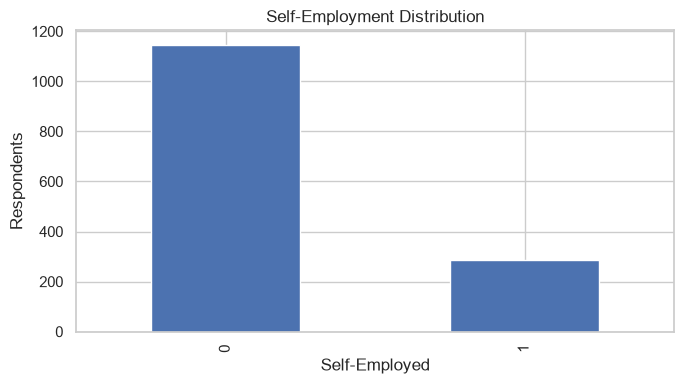

In [289]:
df["Are you self-employed?"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Self-Employment Distribution"
)

plt.xlabel("Self-Employed")
plt.ylabel("Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "self_employment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The company-size variable contains six ordered categories:
- 1-5
- 6-25
- 26-100
- 100-500
- 500-1000
- More than 1000

The variable is ordinal, not nominal.

**Data-Preparation Decision**
- Retain self-employment.
- Retain company size for applicable respondents.
- Preserve the natural ordering of company-size categories.
- Do not treat the company-size categories as arbitrary nomincal labels.
- Do not impute company size for self-employed respondents.
- If included in clustering, represent company size with an ordinal-aware representation or a defensible categorical ordering.

#### 13.2 Technology Employer and Technology Role

In [290]:
pd.crosstab(
    df["Is your employer primarily a tech company/organization?"],
    df["Is your primary role within your company related to tech/IT?"],
    margins=True,
    dropna=False
)

Is your primary role within your company related to tech/IT?,0.0,1.0,NaN,All
Is your employer primarily a tech company/organization?,,,,
0.0,15,248,0,263
1.0,0,0,883,883
NaN,0,0,287,287
All,15,248,1170,1433


The technology-role question has a strong conditional relationship with the technology-employer question.

The observed data show that the technology-role field is populated for respondents whose employer is not primarily a technology company. It is missing for respondents whose employer is classified as a technology company and for the self-employed group.

This is consistent with the survey's question routing and does not mean that all respondents with missing technology-role values have non-technical roles.

**Data-Preparation Decision**
- Preserve the technology-employer variable.
- Do not infer technology-role values from missingness.
- Do not convert missing technology-role values into `No`.
- Exclude the technology-role field from the main clustering matrix because its conditional coverage makes it unsuitable as a general-population feature.
- Retain it for a subgroup analysis of respondents for whom the question was asked.

#### 13.3 Current and Previous Workplace Variables

Current and previous workplace questions often ask similar things, such as whether employers provided mental-health benefits or discussed mental health. However. the questions describe different employers and different periods of respondents' working lives.

A respondent may have experienced different policies and workplace cultures at different employers. Similar wording does not make the variables duplicates.

**Data-Preparation Decision**
- Preserve the conceptual distinction between current and previous workplace experiences.
- Do not merge current and previous employer responses.
- Do not use the previous-employer fields as substitutes for current-employer fields.
- Use the applicability rules established in the missingness investigation.
- Include only features with sufficient coverage and a meaningful interpretation in the final clustering matrix.

### 14. Mental-Health History and Diagnosis Variables

#### 14.1 Distinguish Mental-Health Concepts

The survey contains several questions about mental-health status:
- Family history of mental illness.
- Mental-health disorder in the past.
- Current mental-health disorder.
- Professional diagnosis.
- Treatment history.
- Conditions reported by respondents.

These variables describe different dimensions. They should not be collapsed into a single diagnosis or treatment variable.

In [295]:
for column in [
    "Do you have a family history of mental illness?",
    "Have you had a mental health disorder in the past?",
    "Do you currently have a mental health disorder?",
    "Have you been diagnosed with a mental health "
    "condition by a medical professional?",
    "Have you ever sought treatment for a mental health "
    "issue from a mental health professional?"

]:
    print(f"\n{column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


Do you have a family history of mental illness?


,frequency
Do you have a family history of mental illness?,
Yes,670
No,488
I don't know,275



Have you had a mental health disorder in the past?


,frequency
Have you had a mental health disorder in the past?,
Yes,736
No,451
Maybe,246



Do you currently have a mental health disorder?


,frequency
Do you currently have a mental health disorder?,
Yes,575
No,531
Maybe,327



Have you been diagnosed with a mental health condition by a medical professional?


,frequency
Have you been diagnosed with a mental health condition by a medical professional?,
No,717
Yes,716



Have you ever sought treatment for a mental health issue from a mental health professional?


,frequency
Have you ever sought treatment for a mental health issue from a mental health professional?,
1,839
0,594


The dataset distinguishes:
- Family history from personal history.
- Past mental-health status from current mental-health status.
- Self-reported status from professional diagnosis.
- Diagnosis from treatment-seeking behaviour.

These distinctions are analytically meaningful.

**Data-Preparation Decision**
- Retain these five core variables as separate features, subject to the final feature-selection assessment.
- Standardise binary representations without changing their meaning.
- Preserve `Maybe` where present.
- Do not infer diagnosis from treatment history.
- Do not infer current mental-health status from historical diagnosis.
- Do not merge family history with personal mental-health history.
- Do not treat the condition-description fields as equivalent to the core status variables.

### 15. Work Impact Investigation

#### 15.1 Productivity and Work Interference

The survey includes several variables describing the impact of mental-health issues on the work.

These include:
- Whether productivity is affected.
- Percentage of work time afftected.
- Interference with work when treated effectively.
- Interference with work when not treated effectively.

These questions measure different aspects of work impact and should not be treated as exact duplicates.

In [300]:
for column in [
    "Do you believe your productivity is ever affected by a "
    "mental health issue?",
    "If you have a mental health issue, do you feel that it "
    "interferes with your work when being treated effectively?",
    "If you have a mental health issue, do you feel that it "
    "interferes with your work when NOT being treated effectively?"
]:
    print(f"\n{column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


Do you believe your productivity is ever affected by a mental health issue?


,frequency
Do you believe your productivity is ever affected by a mental health issue?,
NaN,1146
Yes,204
Unsure,38
Not applicable to me,31
No,14



If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?


,frequency
"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?",
Not applicable to me,557
Sometimes,369
Rarely,322
Never,120
Often,65



If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?


,frequency
"If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",
Often,538
Not applicable to me,468
Sometimes,363
Rarely,52
Never,12


In [301]:
pd.crosstab(
    df[
        "If you have a mental health issue, do you feel that "
        "it interferes with your work when being treated effectively?"
    ],
    df[
        "If you have a mental health issue, do you feel that it "
        "interferes with your work when NOT being treated effectively?"
    ],
    margins=True
)

"If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",Never,Not applicable to me,Often,Rarely,Sometimes,All
"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?",,,,,,
Never,9,1,38,18,54,120
Not applicable to me,1,452,35,8,61,557
Often,0,1,56,3,5,65
Rarely,1,5,169,20,127,322
Sometimes,1,9,240,3,116,369
All,12,468,538,52,363,1433


The two work-interference questions are complementary. They describe respondents' reported experience under different treatment circumstances.

The untreated-effectiveness question has no missing values, and its response distribution is particularly informative:
- Often: 538
- Not applicable to me: 468
- Somteimes: 363
- Rarely: 52
- Never: 12

The effectively-treated question also has no missing values.

**Data-Preparation Decision**
- Retain the two work-interference variables as distinct features.
- Preserve the ordinal response structure.
- Keep `Not applicable to me` distinct fron `Never`.
- Retain the productivity-affected question as a separate feature.
- Exclude the percentage-of-work-time follow-up from the main clustering matrix because it is highly sparse and conditional.
- Do not impute the percentage follow-up.

### 16. Workplace Disclosure, Stigma, and Support

#### 16.1 Disclosure and Perceived Consequences

The dataset contains several variables describing whether respondents feel comfortable discussing mental-health issues with colleagues, supervisors, employers, clients, and potential employers. These questions should be treated as related but distinct dimensions of disclosure.

In [306]:
for column in [
    "Do you think that discussing a mental health disorder with "
    "your employer would have negative consequences?",
    "Do you think that discussing a physical health issue with "
    "your employer would have negative consequences?",
    "Would you feel comfortable discussing a mental health "
    "disorder with your coworkers?",
    "Would you feel comfortable discussing a mental health "
    "disorder with your direct supervisor(s)?",
    "Do you feel that being identified as a person with a mental "
    "health issue would hurt your career?",
    "Do you think that team members/co-workers would view you "
    "more negatively if they knew you suffered from a mental health issue?",
    "Would you be willing to bring up a physical health issue "
    "with a potential employer in an interview?",
    "Would you bring up a mental health issue with a potential "
    "employer in an interview?"
]:
    print(f"\n{column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


Do you think that discussing a mental health disorder with your employer would have negative consequences?


,frequency
Do you think that discussing a mental health disorder with your employer would have negative consequences?,
Maybe,487
No,438
NaN,287
Yes,221



Do you think that discussing a physical health issue with your employer would have negative consequences?


,frequency
Do you think that discussing a physical health issue with your employer would have negative consequences?,
No,837
NaN,287
Maybe,268
Yes,41



Would you feel comfortable discussing a mental health disorder with your coworkers?


...

,frequency
Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?,
Maybe,591
"Yes, I think they would",403
"No, I don't think they would",348
"No, they do not",49
"Yes, they do",42



Would you be willing to bring up a physical health issue with a potential employer in an interview?


,frequency
Would you be willing to bring up a physical health issue with a potential employer in an interview?,
Maybe,633
No,441
Yes,359



Would you bring up a mental health issue with a potential employer in an interview?


,frequency
Would you bring up a mental health issue with a potential employer in an interview?,
No,883
Maybe,438
Yes,112


These questions measure different contexts:
- Employer disclosure.
- Coworker disclosure.
- Supervisor disclosure.
- Physical-health disclosure.
- Mental-health disclosure.
- Perceived career consequences.
- Interview disclosure.

The physical-health questions provide a useful comparison with mental-health disclosure. They should not be merged with mental-health questions.

**Data-Preparation Decision**
- Retain the core disclosure and stigma variables as distinct catergorical features where their coverage is adequate.
- Standardise response labels without collapsing meaningfull distinctions.
- Preserve `Maybe` and uncertainty categories.
- Keep physical-health comparison questions separate from mental-health questions.
- Exclude follow-up questions with extremely restricted applicability from the main clustering matrix.

#### 16.2 Workplace Support and Negative Experiences

In [312]:
for column in [
    "Does your employer provide mental health benefits as part "
    "of healthcare coverage?",
    "Has your employer ever formally discussed mental health "
    "(for example, as part of a wellness campaign or other "
    "official communication)?",
    "Does your employer offer resources to learn more about "
    "mental health concerns and options for seeking help?",
    "Is your anonymity protected if you choose to take advantage "
    "of mental health or substance abuse treatment resources "
    "provided by your employer?",
    "Do you feel that your employer takes mental health as "
    "seriously as physical health?",
    "Have you heard of or observed negative consequences for "
    "co-workers who have been open about mental health issues "
    "in your workplace?",
    "Have you observed or experienced an unsupportive or badly "
    "handled response to a mental health issue in your current "
    "or previous workplace?"
]:
    print(f"\n{column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("frequency")
    )


Does your employer provide mental health benefits as part of healthcare coverage?


,frequency
Does your employer provide mental health benefits as part of healthcare coverage?,
Yes,531
I don't know,319
NaN,287
No,213
Not eligible for coverage / N/A,83



Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?


,frequency
"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",
No,813
NaN,287
Yes,230
I don't know,103



Does your employer offer resources to learn more about mental health concerns and options for seeking help?


...

,frequency
Do you feel that your employer takes mental health as seriously as physical health?,
I don't know,493
Yes,350
No,303
NaN,287



Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?


,frequency
Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?,
No,1048
NaN,287
Yes,98



Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?


,frequency
Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?,
No,567
Maybe/Not sure,346
"Yes, I observed",264
"Yes, I experienced",167
NaN,89


The workplace-support variables provide information about organisational resources, confidentiality, formal communication, perceived equality of treatment, and observed negative consequences. They are conceptually related but not interchangeable.

**Data-Preparation Decision**
- Preserve the distinct workplace-support dimensions.
- Standardise equivalent response labels.
- Preserve `I don't know` as distinct from `No`.
- Do not impute missing current-employer values for self-employed respondents.
- Retain the unsupportive-response variable because it has comparatively low missingness and captures an important workplace-experience dimension.
- Evaluate association during data preparation and feature selection so that highly similar workplace variables do not unintentionally dominate the clustering representation.

### 17. Remote Work Investigation

#### 17.1 Remote-Work Distribution

In [316]:
(
    df["Do you work remotely?"]
    .value_counts(dropna=False)
    .to_frame("frequency")
)

,frequency
Do you work remotely?,
Sometimes,757
Always,343
Never,333


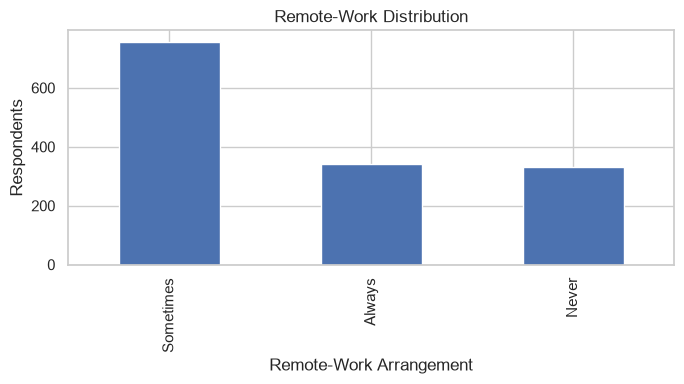

In [327]:
df["Do you work remotely?"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Remote-Work Distribution"
)

plt.xlabel("Remote-Work Arrangement")
plt.ylabel("Respondents")
plt.tight_layout()
plt.savefig(
    Path(FIGURES_PATH) / "remote_work_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Remote work is represented by three categories:
- Always
- Sometimes
- Never

There are no missing values.

**Data-Preparation Decision**

Retain the remote-work variable as an ordinal or categorical employment feature. Preserve all three categories.

### 18. Feature Redundancy and Conceptual Overlap

#### 18.1 Distinguishing Redundancy from Related Information

Two variables are not redundant merely because they ask similar questions. Redundancy exists when a variable contributes essentially the same information as another variable. Conceptual overlap exists when variables describe related but distinct apsects of a broader construct.

The following distinctions are important:

| Variables | Decision | Reason |
| :--- | :--- | :--- |
| Current employer vs previous employer benefits | Keep distinct | Different employers and time periods |
| Current mental-health status vs past history | Keep distinct | Different time dimensions |
| Professional diagnosis vs treatment history | Keep distinct | Diagnosis and treatment are not equivalent |
| Physical-health vs mental-health disclosure | Keep distinct | Useful comparison of stigma |
| Coworker vs supervisor disclosure | Keep distinct | Different workplace relationships |
| Residence country vs work country | Keep distinct | 26 respondents differ |
| Residence state vs work state | Keep distinct | Different geographic contexts |
| Effectively treated vs not effectively treated work interference | Keep distinct | Different treatment circumstances |
| Interview physical-health vs mental-health explanations | Keep distinct | Different topics |
| Current diagnosis vs suspected condition | Keep distinct | Different levels of diagnostic certainty |

#### 18.2 Exact Duplicates versus Highly Associated Features

There are no exact duplicate columns. However, K-Modes uses categorical mismatches when calculating dissimilarity. If several variables measure closely related aspects of one construct, that construct may receive disproportionate influence in the final clustering.

For example, employer benefits, employer resources, awareness of benefits, formal mental-health communication, and confidentiality are all related to workplace support.

**Data-Preparation Decision**
- Retain conceptually distinct features initially.
- Investigate categorical association among candidate features during data preparation.
- Remove features only where they are demonstrably redundant, excessively sparse, or contribute no meaningful clustering information.
- Avoid removing variables merely because they are related.
- Avoid retaining multiple nearly interchangeable features that would overweight one construct.

### 19. Clustering Suitability Assessment

#### 19.1 Suitability Criteria

A variable should not be included in the main clustering matrix merely because it exists in the dataset.

The following criteria will guide feature selection:
1. **Coverage:** sufficient observed responses for the intended clustering population.
2. **Interpretability:** categories have clear and consistent meanings.
3. **Analytical relevance:** the variable contributes information relevant to the project objective.
4. **Cardinality:** the number of categories is manageable and not dominated by free text.
5. **Noise:** the variable does not introduce excessive spelling variation, ambiguous responses, or unstructured text.
6. **Redundancy:** the variable does not duplicate information already represented by another feature.
7. **Applicability:** missingness is not so conditional that the feature becomes misleading in a full-population analysis.
8. **Ethical appropriateness:** the feature does not introduce inappropriate sensitive-attribute influence into clustering.

#### 19.2 Features Unsuitable for the Main Clustering Matrix

The following fields should not be included as raw clustering features:

| Variable/group | Decision | Reason |
| :--- | :--- | :--- |
| Raw gender | Exclude | High-cardinality free text and sensitive demographic attribute |
| Country of residence | Exclude | High-cardinality geography |
| Country of work | Exclude | High-cardinality geography |
| US state of residence | Exclude | Geographically restricted and sparse |
| US state of work | Exclude | Geographically restricted and sparse |
| Raw work-position field | Transform | Multi-select field; complete combinations create excessive cardinality |
| Three raw condition-description fields | Exclude as raw features | Multi-select, sparse, clinically sensitive and inconsistent free text |
| Two interview explanation fields | Exclude | Free text with very high cardinality |
| Client disclosure impact | Exclude | 90% missing and conditional |
| Work-time percentage | Exclude | 85.8% missing and conditional |
| Observed-disclosure influence | Exclude | 54.2% missing and limited applicability |
| Primary technology role | Exclude | Conditional coverage and 81.6% missing |
| Medical coverage question | Exclude from main matrix | 80% missing and restricted applicability |
| Self-employment-specific resource/disclosure/productivity fields | Exclude from main matrix | Restricted subgroup coverage |
| Previous-employer questions | Exclude from full-population matrix unless applicability is explicitly encoded | 11.8% structural missingness for respondents without previous employers |

#### 19.3 Features Suitable for Further Consideration

The following variables are suitable candidates for the main clustering feature set, subject to final association and feature-selection analysis:
- Self-employment.
- Company size, with applicability handled appropriately.
- Technology-employer status, with applicability handled appropriately.
- Current workplace support and communication variables with sufficient coverage.
- Current workplace disclosure and perceived-consequence variables with sufficient coverage.
- Family history of mental illness.
- Past mental-health disorder.
- Current mental-health disorder.
- Professional diagnosis.
- Treatment history.
- Work interference when treated effectively.
- Work interference when not treated effectively.
- Productivity affected by mental-health issues, where the variable is applicable.
- Remote-work arrangement.
- Age, after invalid values are corrected and its influence is evaluated.

The final feature set must not be assumed to include every candidate. Feature selection must consider coverage, redundancy, category distribution, and the effect of the feature on the clustering distance.

### 20. Final Findings and Data Preparation Decisions

#### 20.1 Dataset Overview

The OSMI 2016 Mental Health in Tech dataset contains **1,433 respondents and 63 variables**.

The dataset is predominantly categorical and covers employment characteristics, workplace support, mental-health disclosure, perceived stigma, mental-health history, work impact, demographics, geography, and remote work.

The dataset is suitable for further unsupervised-learning preparation, but it requires substantial cleaning and feature engineering before clustering.

No exact duplicate rows or exact duplicate columns were found.

#### 20.2 Data-Quality Issues Requiring Correction

**Age**

Five values are invalid or implausible:
- 3
- 15
- 17
- 99
- 323

**Decision:** convert these five values to missing. Do not guess replacement ages. Retain valid ages and evaluate the need for imputation during representation.

**Gender**

The gender field contains 70 distinct non-missing response, including spelling variants, inconsistent capitalisation, identity descriptions, and free-text responses. It also contains one malformed `M|` value and three missing values.

**Decision:** standardise unambiguous spelling and formatting variants, preserve meaningful gender identities, correct the malformed `M|` values to `Male` based on its unambiguous context, and exclude raw gender from main clustering matrix. Sound categories for gender are `Female`, `Male`, and `Other`. Retain the cleaned field for descriptive profiling.

**Pipe-Separated Responses**

The pipe character is used in three genuine multi-select fields:
1. Diagnosed conditions associated with current mental-health status.
2. Suspected conditions.
3. Professionally diagnosed conditions.

It is also used in the work-position field to represent multiple roles.

**Decision:** split these fields on the pipe delimiter, trim whitespace, standardise clear label variants, and preserve each selected response. Convert suitable multi-select fields into multi-hot indicators only if they are retained for a separate analysis. Do not treat complete combinations as independent categories.

The `M|` gender value is a malformed response, not a genuine multi-select answer.

**Free-Text Fields**

The two interview explanation columns contain highly diverse qualitative responses. They are not suitable as raw categorical features.

**Decision:** retain the original text for qualitative interpretation, standardise whitespace, and exclude both fields from the main clustering matrix. Do not impute text.

#### 20.3 Missingness Decisions

Missingness is not unformly random. Several patterns are explained by survey routing.

**Current-Employer Questions**

The 287 missing values in the current-employer section correspond to self-employed respondents.

**Decision:** do not impute these values or convert them to `No`. Retain the variables for applicable respondents, but exclude fields with restricted coverage from the full-population clustering matrix unless a defensible representation of applicability is engineered.

**Previous-Employer Questions**

The 169 missing values in the previous-employer section correspond to respondents who report having no previous employers.

**Decision:** do not impute these values or convert them to `No`. Preserve the previous-employer information for descriptive or subgroup analysis. Do not use these fields as ordinary full-population clustering features without explicitly representing applicability.

**Self-Employment-Specific Questions**

Several variables have 1,146 missing values and 287 observed responses. Their missingness is associated with the survey's self-employment routing.

**Decision:** retain them for subgroup analysis, but exclude them from the main full-population clustering matrix.

**Work-Time Percentage**

The worlk-time percentage variable has 85.8% missingness and is conditional on productivity being affected.

**Decision:** exclude it from the main clustering matrix. Retain it for desceriptive analysis of respondents who report productivity effects.

**Client Disclosure Impact**

The client disclosure impact variable has 90% missingness and is conditional on disclosure.

**Decicion:** remove it from the main clustering feature set. Retain it only for a focised descriptive analysis.

**Observed-Disclosure Influence**

The observed-disclosure influence variable has 54.2% missingness and limited applicability.

**Decision:** exclude it from the full-population clustering matrix. Retain it for a separate analysis of disclosure experiences.

**Geographic State Variables**

State and territory responses are applicable only to US respondents.

**Decision:** do not impute state values for non-US respondents. Retain these fields for geographic analysis but exclude them from clustering.

#### 20.4 Feature Removal and Exclusion Decisions

The following variables or groups should be excluded from the main clustering matrix:
- Raw gender.
- Country of residence.
- Country of work.
- US state of residence.
- US state of work.
- Raw free-text interview explanations.
- Raw condition-description fields.
- Raw work-position field before multi-select transformation.
- Work-time percentage.
- Client disclosure impact.
- Observed-disclosure influence.
- Primary technology role.
- Restricted-coverage self-employment-specific fields.
- Previous-employer fields where applicability cannot be represented reliably in the full-populate matrix.

These exclusions are based on high cardinality, sparse coverage, conditional applicability, unstructured text, or the risk of introducing irrelevant or disproportionate influence into clustering.

**Important:** exclusion from the clustering matrix does not mean that the original columns should be deleted from the source-preserving cleaned dataset. They should remain available for auditing, interpretation, and descriptive analysis unless they are explicitly removed from the analytical dataset for a documented reason.

### 20.5 Features to Retain and Prepare

The following variables are candidates for the clustering feature set:
- Self-employment.
- Company size.
- Technology-employer status.
- Current workplace support and communication.
- Current workplace confidentiality and perceived consequences.
- Workplace disclosure comfort.
- Family history of mental illness.
- Past mental-health history.
- Current mental-health status.
- Professional diagnosis.
- Treatment history.
- Work interference when effectively treated.
- Work interference when not effectively treated.
- Productivity impact.
- Remote-work arrangement.
- Age, after invalid values are corrected.

The final set must be confirmed through the feature-selection process during data preparation. In particular, features with conditional missingness must not be included without a defensible treatment of applicability.

#### 20.6 Imputation Policy

Imputation must be conservative. The following rules apply:
1. Do not impute structurally missing values.
2. Do not convert missing values to `No`.
3. Do not impute free-text responses.
4. Do not infer diagnoses or conditions.
5. Do not infer missing employer information from other employer fields.
6. Do not impute geographic state for non-US respondents.
7. Investigate the missingness mechanism before imputing any feature.
8. Where a retained feature has a small number of genuinely missing values, use an imputation strategy appropriate to its data type and distribution.
9. Preserve an indicator of missingness where it carries mneaningful information and is not simply a survey-routing artefact.

#### 20.7 Multiple-Select Transformation Policy

The following fields require multi-select processing:
- The three mental-health condition-description fields.
- Work position.

The preparation workflow must:
1. Split on `|`.
2. Trim whitespace.
3. Standardise labels.
4. Investigate inconsistent or ambiguous categories.
5. Preserve multiple selections.
6. Avoid treating full combinations as unique categories.
7. Create multi-hot indicators only for features selected for a justified analytical purpose.

The condition-description fields should not be included automatically in the main clustering matrix.

### 20.8 Final Methodology Position

The dataset is suitable for further preparation, but the raw 63-column structure should not be used directly for clustering.

The most important preparation tasks are:
- Correct invalid ages.
- Standardise categorical labels.
- Resolve malformed responses.
- Process pipe-separated multi-select fields.
- Preserve distinctions between missing, unknown, uncertain, and not applicable.
- Handle survey-routing missingness without inappropriate imputation.
- Exclude sparse and restricted-coverage variables from the full-population clustering matrix.
- Exclude raw free text and high-cardinality geographic variables from clustering.
- Evaluate feature association and redundancy before finalising the clustering matrix.
- Construct a consistent categorical representation suitable for K-Modes and HDBSCAN.

The data preparation phase should produce a clean, well-documented analytical dataset and a final feature matrix whose variables have clear meanings, adequate coverage, and defensible influence on the clustering results.